# DS 4420 Project: Forecasting Daily Tree Pollen in Louisville, KY (Bayesian Linear Regression)

We forecast each day's tree pollen from the previous day's count, the time of year and the weather, using Bayesian linear regression done by hand in NumPy (no scikit-learn, statsmodels or PyMC).

Run this notebook from the `scripts/` folder, since it reads `../data/louisville_merged.csv` (built by `build_dataset.py`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as student_t

np.set_printoptions(suppress=True, precision=3)

## (a) Data

We keep March–June (the tree pollen season) and days that have a pollen count. The target is $y = \log(1 + \text{grains/m}^3)$, because counts range from 0 to over 3,000.

In [2]:
df = pd.read_csv("../data/louisville_merged.csv", parse_dates=["date"])
df = df[df["has_pollen"] & df["month"].between(3, 6)].copy()
df["doy_sq"] = df["doy"] ** 2

features = ["log_tree_lag1", "doy", "doy_sq", "gdd_cum", "tavg_f", "dewpoint_mean_f",
            "rh_mean_pct", "prcp_in", "rain", "wind_avg_mph", "wind_dir_sin", "wind_dir_cos"]
df = df.dropna(subset=features + ["log_tree"])

train = df[df["year"] < 2018]    # 2003-2017
test = df[df["year"] >= 2018]    # 2018-2022

print("Train days:", len(train), " Test days:", len(test))

Train days: 1548  Test days: 576


Standardize every predictor using the **training** mean and standard deviation only, then add a column of 1s for the intercept to build the design matrix $X$.

In [3]:
mu, sd = train[features].mean(), train[features].std()

def design(d):
    Z = ((d[features] - mu) / sd).to_numpy()
    return np.column_stack([np.ones(len(d)), Z])

X_train, X_test = design(train), design(test)
y_train, y_test = train["log_tree"].to_numpy(), test["log_tree"].to_numpy()
n, p = X_train.shape
print("X_train shape:", X_train.shape)

X_train shape: (1548, 13)


## (b) Model and posterior

Data likelihood and Normal-Inverse-Gamma prior (the prior on $\mathbf{w}$ is scaled by $\sigma^2$):

$$\mathbf{y} \mid \mathbf{w}, \sigma^2, X \sim N_n(X\mathbf{w},\ \sigma^2 I_n) \qquad \mathbf{w} \mid \sigma^2 \sim N_p(\mathbf{0},\ \sigma^2 \Sigma_0) \qquad \sigma^2 \sim IG(\alpha_0, \beta_0)$$

Because the prior on $\mathbf{w}$ is scaled by $\sigma^2$, the posterior has a closed form (no Gibbs sampling needed):

$$V_n = (X^TX + \Sigma_0^{-1})^{-1} \qquad \mathbf{w}_n = V_n X^T\mathbf{y}$$

$$\alpha_n = \alpha_0 + \frac{n}{2} \qquad \beta_n = \beta_0 + \frac{1}{2}\left(\mathbf{y}^T\mathbf{y} - \mathbf{w}_n^T V_n^{-1}\mathbf{w}_n\right)$$

We use $\Sigma_0^{-1} = I$ on the standardized predictors (mild shrinkage, like ridge regression), an essentially flat prior on the intercept, and $\alpha_0 = \beta_0 = 1$.

In [4]:
def fit_posterior(X, y, prior_precision=1.0, alpha_0=1.0, beta_0=1.0):
    Sigma_0_inv = np.diag([1e-6] + [prior_precision] * (X.shape[1] - 1))   # ~flat prior on the intercept
    V_n_inv = X.T @ X + Sigma_0_inv
    V_n = np.linalg.inv(V_n_inv)
    w_n = V_n @ X.T @ y
    alpha_n = alpha_0 + len(y) / 2
    beta_n = beta_0 + 0.5 * (y @ y - w_n @ V_n_inv @ w_n)
    return w_n, V_n, alpha_n, beta_n

w_n, V_n, alpha_n, beta_n = fit_posterior(X_train, y_train)
print("alpha_n =", round(alpha_n, 1), " beta_n =", round(beta_n, 1))
print("posterior mean of sigma^2:", round(beta_n / (alpha_n - 1), 3))

alpha_n = 775.0  beta_n = 1070.6
posterior mean of sigma^2: 1.383


## (c) Posterior of each weight

Each weight's marginal posterior is a Student-t with $2\alpha_n$ degrees of freedom, centered at $w_{n,j}$ with scale $\sqrt{\frac{\beta_n}{\alpha_n} V_{n,jj}}$. We report the 95% posterior interval.

In [5]:
t_95 = student_t.ppf(0.975, df=2 * alpha_n)
w_scale = np.sqrt(beta_n / alpha_n * np.diag(V_n))

weights = pd.DataFrame({
    "posterior mean": w_n,
    "95% lower": w_n - t_95 * w_scale,
    "95% upper": w_n + t_95 * w_scale,
}, index=["intercept"] + features)
weights["excludes 0"] = (weights["95% lower"] > 0) | (weights["95% upper"] < 0)
weights.round(3)

,posterior mean,95% lower,95% upper,excludes 0
intercept,3.578,3.520,3.637,True
log_tree_lag1,1.231,1.141,1.322,True
doy,2.636,2.087,3.185,True
doy_sq,-2.943,-3.589,-2.297,True
gdd_cum,-0.861,-1.134,-0.588,True
tavg_f,0.140,-0.271,0.550,False
dewpoint_mean_f,0.650,0.144,1.155,True
rh_mean_pct,-0.362,-0.552,-0.171,True
prcp_in,-0.005,-0.073,0.063,False
rain,0.058,-0.007,0.123,False


## (d) Forecasts and prediction intervals

The posterior predictive distribution for a new day $\mathbf{x}$ is also a Student-t, with $2\alpha_n$ degrees of freedom, center $\mathbf{x}^T\mathbf{w}_n$ and scale $\sqrt{\frac{\beta_n}{\alpha_n}(1 + \mathbf{x}^T V_n \mathbf{x})}$. This gives the prediction intervals directly, without sampling.

In [6]:
def predict(X, w_n, V_n, alpha_n, beta_n, level=0.90):
    center = X @ w_n
    scale = np.sqrt(beta_n / alpha_n * (1 + np.sum((X @ V_n) * X, axis=1)))
    t_crit = student_t.ppf(0.5 + level / 2, df=2 * alpha_n)
    return center, center - t_crit * scale, center + t_crit * scale

y_hat, lo_90, hi_90 = predict(X_test, w_n, V_n, alpha_n, beta_n, 0.90)
_, lo_50, hi_50 = predict(X_test, w_n, V_n, alpha_n, beta_n, 0.50)

print("90% interval coverage:", round(np.mean((y_test >= lo_90) & (y_test <= hi_90)), 3))
print("50% interval coverage:", round(np.mean((y_test >= lo_50) & (y_test <= hi_50)), 3))

90% interval coverage: 0.896
50% interval coverage: 0.549


## (e) Comparison with baselines

- **Day-of-year average:** the average log pollen for that calendar day in the training years (7-day smoothed).
- **Same as yesterday:** today's forecast is yesterday's count.

We also convert forecasts to the CDC tree pollen levels: Low (< 15), Moderate (15–90), High (90–1,500) and Very High (≥ 1,500 grains/m³).

In [7]:
clim = train.groupby("doy")["log_tree"].mean().rolling(7, center=True, min_periods=1).mean()
day_avg = test["doy"].map(clim).fillna(y_train.mean()).to_numpy()
yesterday = test["log_tree_lag1"].to_numpy()

def level(log_counts):
    g = np.expm1(log_counts) + 1e-9
    return np.select([g >= 1500, g >= 90, g >= 15], [3, 2, 1], 0)

rows = []
for name, pred in [("Day-of-year average", day_avg), ("Same as yesterday", yesterday),
                   ("Bayesian regression", y_hat)]:
    rows.append({
        "model": name,
        "RMSE": np.sqrt(np.mean((y_test - pred) ** 2)),
        "MAE": np.mean(np.abs(y_test - pred)),
        "R2": 1 - np.mean((y_test - pred) ** 2) / y_test.var(),
        "level correct": np.mean(level(pred) == level(y_test)),
        "within one level": np.mean(np.abs(level(pred) - level(y_test)) <= 1),
    })
pd.DataFrame(rows).set_index("model").round(3)

,RMSE,MAE,R2,level correct,within one level
model,,,,,
Day-of-year average,1.496,1.119,0.497,0.608,0.941
Same as yesterday,1.549,1.083,0.461,0.627,0.950
Bayesian regression,1.264,0.936,0.641,0.641,0.976


## (f) Prior sensitivity

We refit with weaker and stronger shrinkage on the weights ($\Sigma_0^{-1}$ = 0.01 to 1,000) and check test RMSE and 90% coverage.

In [8]:
for prec in [0.01, 1, 10, 100, 1000]:
    post = fit_posterior(X_train, y_train, prior_precision=prec)
    pred, lo, hi = predict(X_test, *post, 0.90)
    rmse = np.sqrt(np.mean((y_test - pred) ** 2))
    cover = np.mean((y_test >= lo) & (y_test <= hi))
    print(f"prior precision {prec:>7}: RMSE = {rmse:.3f}, 90% coverage = {cover:.3f}")

prior precision    0.01: RMSE = 1.264, 90% coverage = 0.894
prior precision       1: RMSE = 1.264, 90% coverage = 0.896
prior precision      10: RMSE = 1.277, 90% coverage = 0.898
prior precision     100: RMSE = 1.305, 90% coverage = 0.911
prior precision    1000: RMSE = 1.407, 90% coverage = 0.951


## (g) Plot: the 2019 test season

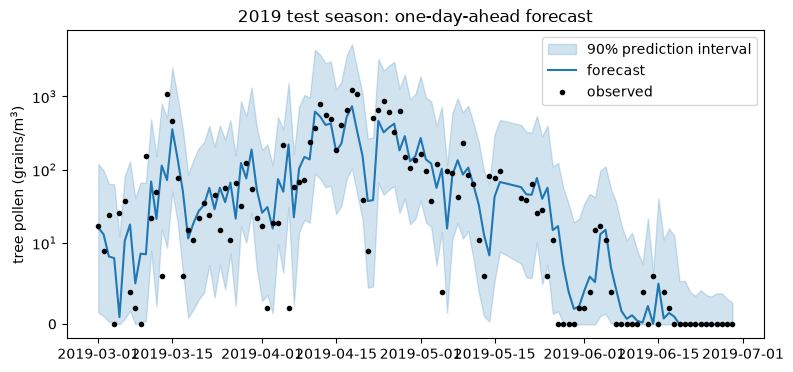

In [9]:
show = (test["year"] == 2019).to_numpy()
dates = test["date"][show]

plt.figure(figsize=(9, 4))
plt.fill_between(dates, np.expm1(lo_90[show]).clip(0), np.expm1(hi_90[show]),
                 color="tab:blue", alpha=0.2, label="90% prediction interval")
plt.plot(dates, np.expm1(y_hat[show]).clip(0), color="tab:blue", label="forecast")
plt.plot(dates, np.expm1(y_test[show]), "k.", label="observed")
plt.yscale("symlog", linthresh=10)
plt.ylabel("tree pollen (grains/m$^3$)")
plt.title("2019 test season: one-day-ahead forecast")
plt.legend()
plt.show();

**Takeaways:** the model beats both baselines (R² 0.64 vs. 0.46–0.50), and its intervals are well calibrated (about 90% of test days fall inside the 90% interval). Most of the skill comes from yesterday's pollen and the time of year; weather adds a few percentage points. The MLP comparison is in `mlp.py`, and the report figures come from `make_figures.py`.